# 04. ReID и согласованность путей

Цель на выходе иметь три ReID-модели, retrieval mAP/rank-1 и история path loss.


в `MyDrive/ML6/`. Исходные видео и старые результаты остаются в прежних папках.
Вычисления читают локальные кадры; результаты нового запуска пишутся в `runs/RUN_ID/`.

In [ ]:
import sys, os, subprocess, importlib.util
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules or Path('/content').is_dir()
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/ML6')
else:
    PROJECT = Path('D:/ML6')
RUN_ID = 'blue_aug_20261112_v2'  # одинаковый во всех 10 ноутбуках; старый run не меняем
BUNDLE = PROJECT / 'notebooks_colab_full'
assert (BUNDLE / 'tracking_lab.py').is_file(), BUNDLE
packages = {'scipy':'scipy', 'pandas':'pandas', 'cv2':'opencv-python-headless',
    'matplotlib':'matplotlib', 'tqdm':'tqdm', 'trackeval':'trackeval==1.3.0',
    'cryptography':'cryptography', 'imageio':'imageio', 'imageio_ffmpeg':'imageio-ffmpeg'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
# Совместимую пару torch/torchvision предоставляет Colab; автоматически её не заменяем.
sys.path.insert(0, str(BUNDLE))
import tracking_lab as tl
assert Path(tl.__file__).resolve() == (BUNDLE / 'tracking_lab.py').resolve(), 'Перезапустите runtime: загружен старый модуль'
assert tl.SCHEMA == 4, 'Перезапустите runtime после обновления исходного кода'
import torch, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Video, HTML, Image
lab = tl.Lab(PROJECT, RUN_ID)
torch.hub.set_dir(str(PROJECT / 'pretrained_cache'))
display(pd.Series(lab.environment(), name='Среда'))
print('Запуск:', RUN_ID, '| Результаты:', lab.root)

Mounted at /content/drive


,Среда
python,"3.13.16 (main, Oct 1 2026, 15:40:24) [GCC 13...."
packages,"{'torch': '2.14.1+cu130', 'torchvision': '0.29..."
device,cuda
gpu,NVIDIA L4


Запуск: blue_aug_20261112_v2 | Результаты: /content/drive/MyDrive/ML6/runs/blue_aug_20261112_v2


Восстановление кадров из архивов на Drive в `/content` с SHA256 каждого JPEG.
 Checkpoint, manifest и архивы остаются на Drive.
Финальные видео здесь не загружаются для анализа.

In [ ]:
LOCAL = '/content/ml6_full_frames' if IN_COLAB else str(lab.path('local_frames'))
tl.cache_frames(lab, LOCAL, splits=('train','val','dev'))
print('Кадры:', lab.frame_cache_root)

Локальный кэш:   0%|          | 0/131 [00:00<?, ?архив/s]

Архив → /content:   0%|          | 0.00/26.1M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/27.2M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/304M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/61.9M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/4.66M [00:00<?, ?B/s]

... (103 outputs left out)

Архив → /content:   0%|          | 0.00/9.88M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/154M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/29.2M [00:00<?, ?B/s]

Кадры: /content/ml6_full_frames


Батч `P=8`, `K=4`: восемь идентичностей и четыре разных кадра каждой.
Половина личностей по возможности берётся из одной сцены — сложные отрицательные
примеры. Ключ личности `(video_id, track_id)` исключает склейку одинаковых ID из разных
роликов. Потеря: batch-hard triplet + supervised contrastive и согласованность с
чистыми stop-gradient признаками. Для каждого реального наблюдения выбирается один
тип из той же смеси. PGD меняет только выбранные кропы, сохраняя остальных участников
P×K-батча для metric mining. Патчи оптимизируются отдельно от случайных перекрытий.
Начальная адаптация и постепенное усиление совпадают с протоколом детектора.


Добавлена **supervised adaptation идеи согласованности путей**
[Lu et al., CVPR 2024](https://github.com/amazon-science/path-consistency).
Для трёх кадров A,B,C вычисляются `P_AC=softmax(Z_A Z_Cᵀ/τ)` и
`P_ABC=softmax(Z_A Z_Bᵀ/τ) softmax(Z_B Z_Cᵀ/τ)`.
Потеря = JSD(P_AC,P_ABC) + CE по известным ID для обоих путей, в двух направлениях.
CE и metric loss препятствуют вырожденному равномерному решению. Учитываются якоря,
присутствующие во всех трёх кадрах; остальные люди остаются отвлекающими кандидатами.
Исчезновения между кадрами дополнительно обрабатывает трекер. Gap=1,2,4,8 на реальной
сетке кадров.

,Идентичностей,Троек кадров,P,K
0,4698,21706,8,4


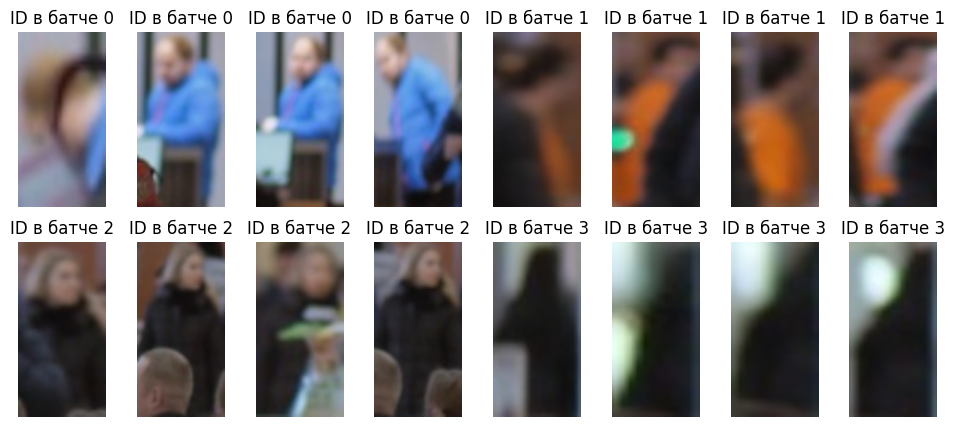

In [ ]:
groups=tl.identity_groups(lab.records('train'),lab.cfg['reid_K'])
paths=tl.path_triplets(lab.records('train'))
display(pd.DataFrame([{'Идентичностей':len(groups),'Троек кадров':len(paths),'P':lab.cfg['reid_P'],'K':lab.cfg['reid_K']}]))
crops,labels,items=tl.pk_batch(lab,groups)
fig,axes=plt.subplots(2,8,figsize=(12,5))
for ax,x,label in zip(axes.flat,crops[:16],labels[:16]):
    ax.imshow(x.permute(1,2,0)); ax.set_title(f'ID в батче {int(label)}'); ax.axis('off')
plt.show()

In [ ]:
assert lab.device.type == 'cuda'
if not lab.path('artifacts/reid_initial_validation.csv').exists():
    initial=tl.ReID().to(lab.device)
    initial.load_state_dict(tl.checked_checkpoint(lab.path('checkpoints/initial/reid.pt'))['model'])
    initial_retrieval=tl.validate_reid(lab,initial,tl.identity_groups(lab.records('val')))
    initial_retrieval.to_csv(lab.path('artifacts/reid_initial_validation.csv'),index=False)
    display(initial_retrieval)
    del initial
for variant in tl.VARIANTS:
    model=tl.train_reid(lab,variant)
    del model
    torch.cuda.empty_cache()

,scenario,mAP,rank1,queries,excluded_queries
0,clean,0.242191,0.360,200,0
1,pgd,0.009435,0.000,200,0
2,photo,0.243908,0.375,200,0
3,jpeg,0.195667,0.295,200,0
4,noise,0.140790,0.200,200,0
5,blur,0.232789,0.355,200,0
6,geometry,0.232153,0.375,200,0
7,occlusion,0.206417,0.305,200,0


plain ReID 1:   0%|          | 0/250 [00:00<?, ?it/s]

 scenario      mAP  rank1  queries  excluded_queries
    clean 0.392735  0.515      200                 0
      pgd 0.011004  0.000      200                 0
    photo 0.385933  0.505      200                 0
     jpeg 0.372818  0.465      200                 0
    noise 0.173675  0.185      200                 0
     blur 0.391054  0.510      200                 0
 geometry 0.377703  0.505      200                 0
occlusion 0.358134  0.430      200                 0


plain ReID 2:   0%|          | 0/250 [00:00<?, ?it/s]

 scenario      mAP  rank1  queries  excluded_queries
    clean 0.390828  0.520      200                 0
      pgd 0.008619  0.000      200                 0
    photo 0.381329  0.495      200                 0
     jpeg 0.377587  0.495      200                 0
    noise 0.290751  0.365      200                 0
     blur 0.386101  0.510      200                 0
 geometry 0.357772  0.445      200                 0
occlusion 0.357690  0.465      200                 0


plain ReID 3:   0%|          | 0/250 [00:00<?, ?it/s]

... (51 outputs left out)

adversarial ReID 9:   0%|          | 0/250 [00:00<?, ?it/s]

 scenario      mAP  rank1  queries  excluded_queries
    clean 0.453791  0.565      200                 0
      pgd 0.170664  0.085      200                 0
    photo 0.442099  0.535      200                 0
     jpeg 0.451562  0.555      200                 0
    noise 0.445729  0.560      200                 0
     blur 0.449568  0.555      200                 0
 geometry 0.431019  0.530      200                 0
occlusion 0.431952  0.525      200                 0


adversarial ReID 10:   0%|          | 0/250 [00:00<?, ?it/s]

 scenario      mAP  rank1  queries  excluded_queries
    clean 0.448555  0.565      200                 0
      pgd 0.176684  0.090      200                 0
    photo 0.438788  0.545      200                 0
     jpeg 0.447634  0.570      200                 0
    noise 0.442388  0.560      200                 0
     blur 0.447514  0.570      200                 0
 geometry 0.428692  0.530      200                 0
occlusion 0.427675  0.520      200                 0


,Воздействие,Примеров
0,Обычные,80000


,real_observations,unique_real_observations,adversarial_factor
epoch,,,
0,32.0,32.0,0.000
1,32.0,32.0,0.249
2,32.0,32.0,0.749
3,32.0,32.0,1.000
4,32.0,32.0,1.000
5,32.0,32.0,1.000
6,32.0,32.0,1.000
7,32.0,32.0,1.000
8,32.0,32.0,1.000


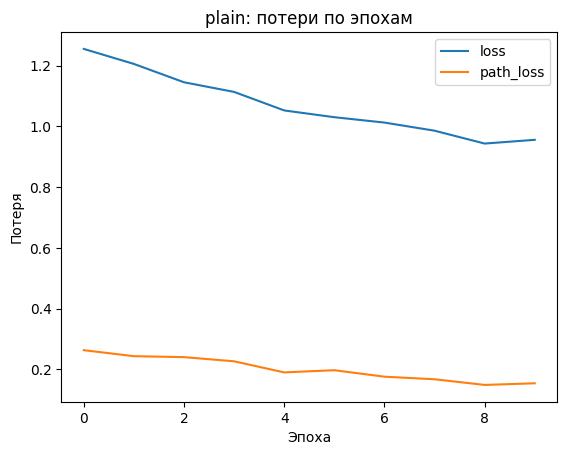

,Воздействие,Примеров
0,JPEG,8026
1,Геометрия,4106
2,Обычные,43903
3,Перекрытие,3910
4,Размытие,4055
5,Шум,4043
6,Яркость / контраст / гамма,11957


,real_observations,unique_real_observations,adversarial_factor
epoch,,,
0,32.0,32.0,0.000
1,32.0,32.0,0.249
2,32.0,32.0,0.749
3,32.0,32.0,1.000
4,32.0,32.0,1.000
5,32.0,32.0,1.000
6,32.0,32.0,1.000
7,32.0,32.0,1.000
8,32.0,32.0,1.000


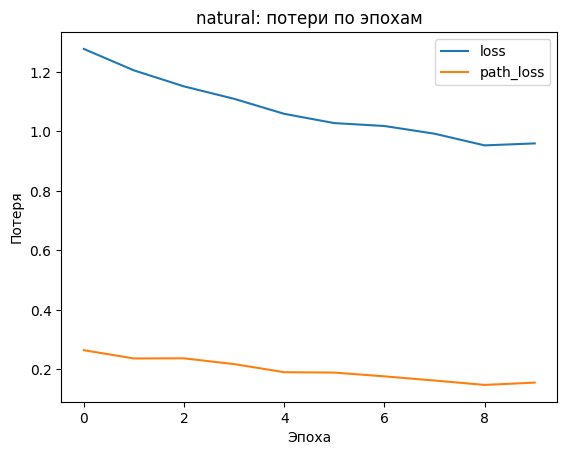

,Воздействие,Примеров
0,Adversarial-патч,600
1,JPEG,8007
2,PGD,9665
3,Геометрия,3977
4,Обычные,34385
5,Перекрытие,3325
6,Размытие,3970
7,Шум,3985
8,Яркость / контраст / гамма,12086


,real_observations,unique_real_observations,adversarial_factor
epoch,,,
0,32.0,32.0,0.000
1,32.0,32.0,0.249
2,32.0,32.0,0.749
3,32.0,32.0,1.000
4,32.0,32.0,1.000
5,32.0,32.0,1.000
6,32.0,32.0,1.000
7,32.0,32.0,1.000
8,32.0,32.0,1.000


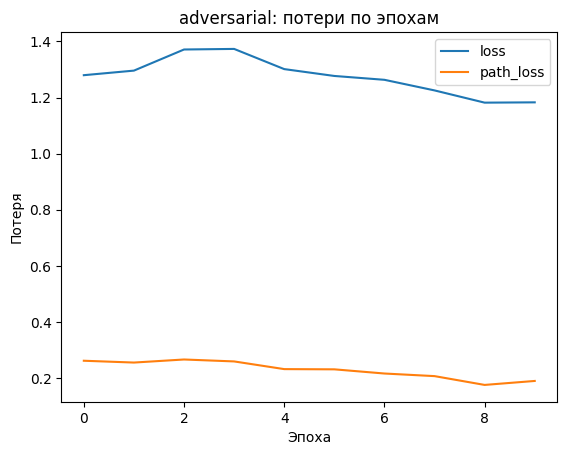

,Сценарий,mAP,Rank-1,Запросов,excluded_queries,Вариант,Эпоха
0,clean,0.392735,0.515,200,0,plain,1
1,pgd,0.011004,0.000,200,0,plain,1
2,photo,0.385933,0.505,200,0,plain,1
3,jpeg,0.372818,0.465,200,0,plain,1
4,noise,0.173675,0.185,200,0,plain,1
...,...,...,...,...,...,...,...
235,jpeg,0.451562,0.555,200,0,adversarial,9
236,noise,0.445729,0.560,200,0,adversarial,9
237,blur,0.449568,0.555,200,0,adversarial,9
238,geometry,0.431019,0.530,200,0,adversarial,9


,variant,epoch,scenario,Изменение mAP
0,plain,1,clean,0.150544
1,plain,1,pgd,0.001570
2,plain,1,photo,0.142026
3,plain,1,jpeg,0.177150
4,plain,1,noise,0.032885
...,...,...,...,...
235,adversarial,9,jpeg,0.255895
236,adversarial,9,noise,0.304939
237,adversarial,9,blur,0.216779
238,adversarial,9,geometry,0.198865


In [ ]:
tables=[]
for variant in tl.VARIANTS:
    folder=tl.model_path(lab,'reid',variant).parent
    history=pd.read_csv(folder/'history.csv')
    display(pd.read_csv(folder/'augmentation_counts.csv'))
    display(history[['real_observations','unique_real_observations','adversarial_factor']].groupby(history.epoch).mean())
    history.groupby('epoch')[['loss','path_loss']].mean().plot(title=f'{variant}: потери по эпохам')
    plt.xlabel('Эпоха'); plt.ylabel('Потеря'); plt.show()
    for p in sorted(folder.glob('validation_epoch_*.csv')):
        t=pd.read_csv(p); t['variant']=variant; t['epoch']=int(p.stem.rsplit('_',1)[1]); tables.append(t)
retrieval=pd.concat(tables,ignore_index=True)
display(retrieval.rename(columns={'scenario':'Сценарий','variant':'Вариант','epoch':'Эпоха','rank1':'Rank-1','queries':'Запросов'}))
initial=pd.read_csv(lab.path('artifacts/reid_initial_validation.csv'))
delta=retrieval.merge(initial[['scenario','mAP','rank1']],on='scenario',suffixes=('','_initial'))
delta['Изменение mAP']=delta.mAP-delta.mAP_initial
display(delta[['variant','epoch','scenario','Изменение mAP']])

Retrieval использует разные кадры query/gallery, чистую галерею и изменённый
запрос. Отдельно считаются clean, PGD и каждый natural-тип: mAP и rank-1 на validation-видео.
Это внутривидео person retrieval с глобальным ключом ID, а не межкамерный ReID benchmark.
Лучший checkpoint выбирается по среднему mAP условий, не только по loss.

Обучение улучшило сопоставление людей, но устойчивость к PGD остаётся низкой.
- natural на чистых изображениях выбирает правильного человека первым в 59,5% случаев, исходная модель — в 36%.
- При шуме natural заметно лучше plain: 58,5% против 36,5% правильных первых совпадений.
- Под PGD у plain и natural результат почти нулевой. Обучение с атаками повышает его до 9%, но уступает natural на чистых изображениях.
- Отдельный вклад согласованности путей не проверен: сравнения с обучением без неё нет.
Грустненько